In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("telco_churn_dataset.csv")

In [2]:
df.index.name=None
df.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No


In [3]:
remove_unnecessary=df.drop(columns=['CustomerID'])
remove_unnecessary

,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,46,Female,10,52.47,One year,Electronic check,537.88,No
3,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No
...,...,...,...,...,...,...,...,...
99995,31,Male,49,26.07,Month-to-month,Electronic check,1220.50,No
99996,64,Female,44,123.22,Month-to-month,Mailed check,5384.38,No
99997,48,Other,32,75.37,Month-to-month,Credit card,2372.33,Yes
99998,42,Female,60,114.00,Month-to-month,Mailed check,6826.55,No


In [4]:
df.isnull().sum()

CustomerID        0
Age               0
Gender            0
Tenure            0
MonthlyCharges    0
Contract          0
PaymentMethod     0
TotalCharges      0
Churn             0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
X=df.drop(columns=['CustomerID','Churn'])
Y=df['Churn']
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
X_train.describe()

,Age,Tenure,MonthlyCharges,TotalCharges
count,80000.000000,80000.000000,80000.000000,80000.000000
mean,49.026137,36.597275,79.910830,2926.967711
std,18.177796,20.796784,40.475501,2388.210492
min,18.000000,1.000000,10.000000,-118.430000
25%,33.000000,19.000000,44.690000,963.075000
50%,49.000000,37.000000,79.840000,2271.115000
75%,65.000000,55.000000,115.060000,4385.862500
max,80.000000,72.000000,150.000000,10831.460000


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
trans=ColumnTransformer(transformers=[('trans1',OneHotEncoder(sparse_output=False,drop='first'),['Gender','PaymentMethod']),
                                     ('trans2',OrdinalEncoder(categories=[['Month-to-month','One year','Two year']]), 
                                         ['Contract'])
                                     ],
                                     remainder='passthrough'
)
trans.fit(X_train)
trans.fit(X_test)

,transformers,"[('trans1', ...), ('trans2', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,categories,'auto'
,drop,'first'
,sparse_output,False


In [29]:
X_train_transform=trans.fit_transform(X_train)
X_test_transform=trans.fit_transform(X_test)


In [30]:
from sklearn.preprocessing import StandardScaler
scale=StandardScaler()
scale.fit(X_train_transform)
X_train_scale=scale.transform(X_train_transform)
X_test_scale=scale.transform(X_test_transform)


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
model = LogisticRegression()
model.fit(X_train_scale,Y_train)
Y_predict=model.predict(X_test_scale)
accuracy_score_is=accuracy_score(Y_test,Y_predict)
print("accuracy_score is",accuracy_score_is)

accuracy_score is 0.7234


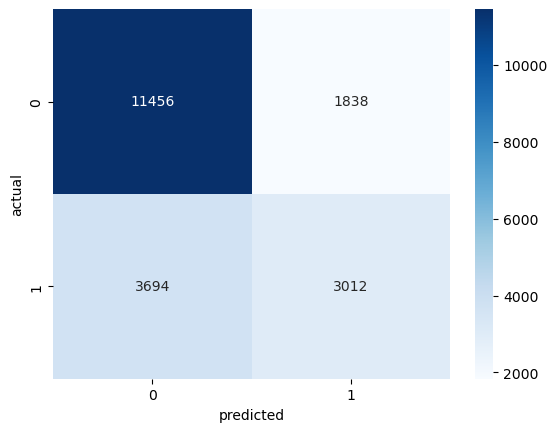

In [36]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cal_matrix=confusion_matrix(Y_test,Y_predict)
sns.heatmap(cal_matrix,annot=True,fmt='d',cmap='Blues')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()

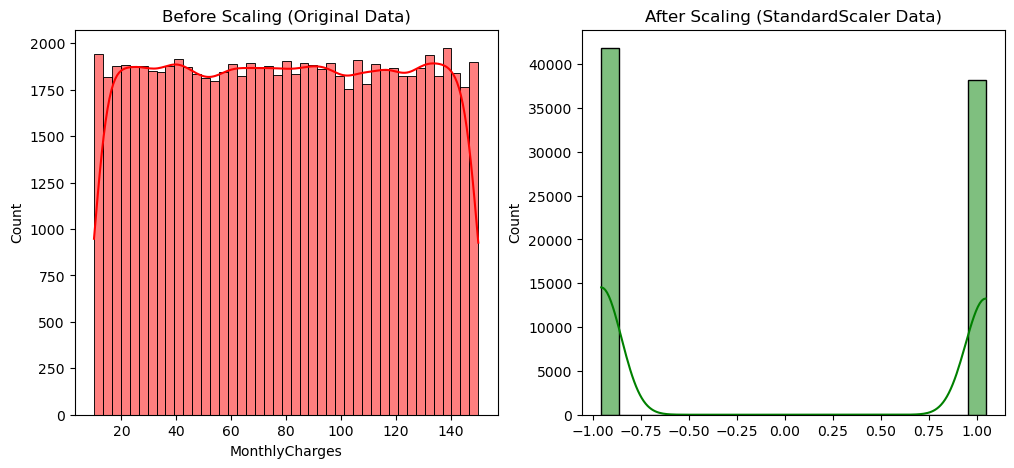

In [37]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(X_train['MonthlyCharges'], kde=True, ax=axes[0], color='red')
axes[0].set_title('Before Scaling (Original Data)')
sns.histplot(X_train_scale[:, 0], kde=True, ax=axes[1], color='green')
axes[1].set_title('After Scaling (StandardScaler Data)')

plt.show()